# Monetary Policy and the 2007 US Housing Bubble
### A Structural Vector Autoregressive Analysis

*Companion notebook to a Master's Thesis in Economics, Tampere University, 2026.*

**Research question.** Did the Federal Reserve's accommodative policy, the deviations of the Federal Funds Rate (FFR) from the Taylor Rule during 2001–2004, fuel the 2000s US housing bubble? And how did the transmission differ across metropolitan areas with different housing supply elasticities?

**Approach.** Separate 4-variable structural VARs are estimated on monthly data from `1987/01` to `2007/07` for two national aggregates and five metropolitan areas. The sample starts with the Greenspan era and the start of the Case-Shiller indices, and it ends just before the August 2007 outbreak of the financial crisis. The notebook then asks what house prices would have done without monetary policy shocks from 2001 onward.

**Two monetary transmission channels frame the results:**

1. *Interest rate channel (neoclassical).* The policy rate acts as the risk-free discount factor in the user cost of housing capital (Himmelberg et al., 2005), which changes fundamental house values.
2. *Bank lending and credit supply channel (non-neoclassical).* Policy works through financial frictions, intermediary balance sheets and external finance premiums (Disyatat, 2011; Brunnermeier, 2009). After the FOMC cut its target to 1% in June 2003, the GSE refinancing boom collapsed and originators pivoted to non-conforming loans funded through Private-Label Mortgage-Backed Securities (PLS) and wholesale funding (Justiniano et al., 2022; Drechsler et al., 2022). This fueled speculative buying by a homogeneous marginal buyer pool (Mian & Sufi, 2022).

**Running this notebook.** The datasets are included in `data_csv/`, so it runs immediately and needs no API key (`REFRESH_DATA = False` by default). All logic lives in the `src/` package, and this notebook only calls those functions and presents the results.

In [1]:
%load_ext autoreload
%autoreload 2

from src import config, plots
from src.counterfactual import run_3var_counterfactual, run_counterfactual_analysis
from src.data_processing import compute_permits_per_capita, load_data, prepare_var_data
from src.fred_download import data_files_exist, download_and_save
from src.var_irf import run_var_analysis

## 1. Data Ingestion & Preparation

All series come from FRED and are stored in two files:

| File | Coverage | Contents |
|---|---|---|
| `var_data.csv` | 1987/01–2007/07 | Case-Shiller house price indices, FFR, unemployment, Trimmed Mean PCE inflation |
| `visual_data.csv` | 1959/01–2025/08 | Building permits, population, housing starts, NBER recession indicator |

Set `REFRESH_DATA = True` to fetch everything again from FRED and overwrite the files, which requires `FRED_API_KEY` in a `.env` file.

In [2]:
REFRESH_DATA = False

if REFRESH_DATA or not data_files_exist():
    download_and_save()

In [3]:
df_visuals = load_data(config.VISUALS_DATA_PATH)
df_var = load_data(config.VAR_DATA_PATH)

print(f"Exploratory data: {df_visuals.index.min():%Y-%m} to {df_visuals.index.max():%Y-%m}")
print(f"VAR data:         {df_var.index.min():%Y-%m} to {df_var.index.max():%Y-%m} (N = {len(df_var)})")

Exploratory data: 1959-01 to 2025-08
VAR data:         1987-01 to 2007-07 (N = 247)


The house price indices enter the VAR in logs, so impulse responses read as approximate percentage changes.

In [4]:
df_var_ready = prepare_var_data(df_var)

df_var_ready[['unemp', 'pce_rate', 'ffr', 'cs', 'log_cs']].head()

,unemp,pce_rate,ffr,cs,log_cs
Date,,,,,
1987-01-01,6.6,3.16,6.43,63.963,4.158305
1987-02-01,6.6,3.22,6.10,64.422,4.165455
1987-03-01,6.6,3.41,6.13,64.732,4.170256
1987-04-01,6.3,3.57,6.37,65.129,4.176370
1987-05-01,6.3,3.66,6.85,65.561,4.182981


## 2. Exploratory Data Analysis & Regional Supply Elasticity

### 2.1 Housing Starts and Recessions, 1959–2025
Residential construction is one of the most reliable leading indicators of the US business cycle (Leamer, 2015). Starts typically fall well before a recession begins, and the collapse after 2006 is the largest in the sample.

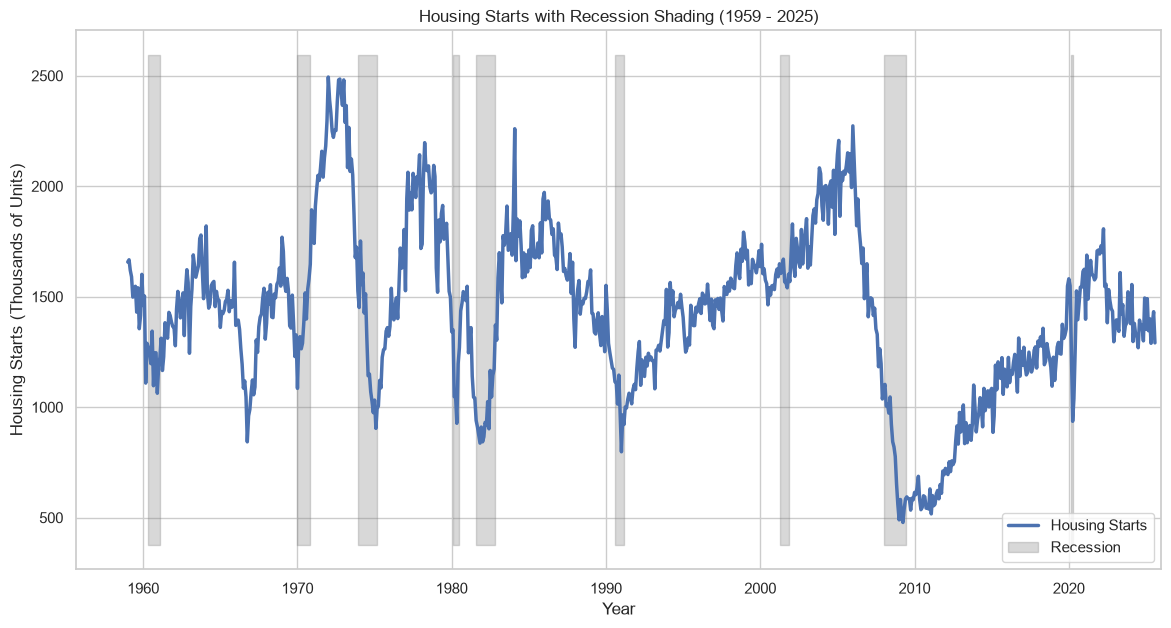

In [5]:
plots.plot_housing_starts(df_visuals)

### 2.2 National and Metro Building Permits per Capita
Permits show how much of a housing demand increase is met by new supply rather than by higher prices (Glaeser & Gyourko, 2018; Glaeser, Gyourko & Saiz, 2008). The five metro areas were chosen to represent distinct regimes:

| Metro | Regime | Permits per 1,000 residents per month, 2000–2007 mean |
|---|---|---|
| Las Vegas | Elastic land supply, explosive construction and speculative boom | 1.69 |
| Charlotte | Lightly regulated, elastic supply | 1.23 |
| Denver | Lightly regulated, elastic supply | 0.73 |
| Cleveland | Stagnating Rust Belt market, prices below replacement cost | 0.26 |
| New York | Heavily regulated, inelastic supply | 0.24 |

The national average over the same period is 0.51.

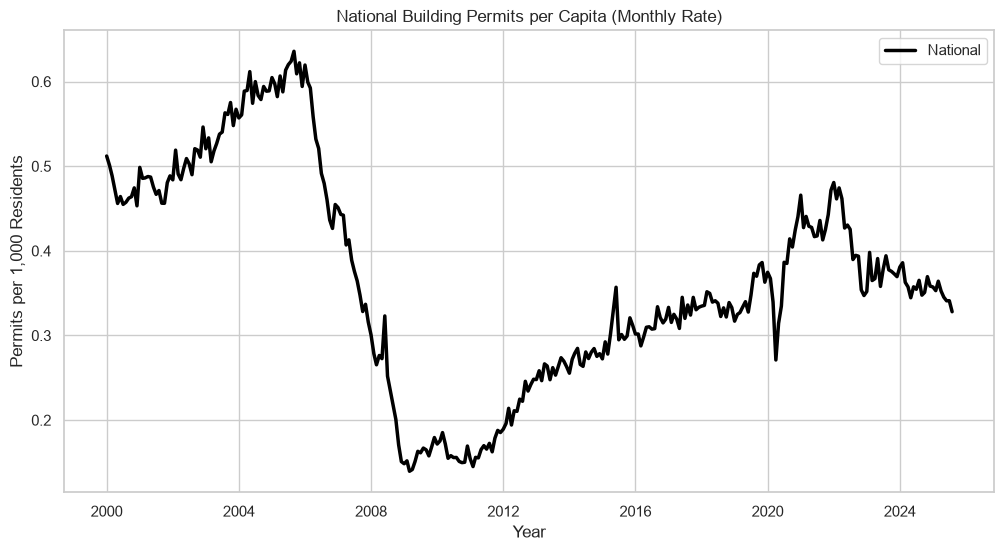

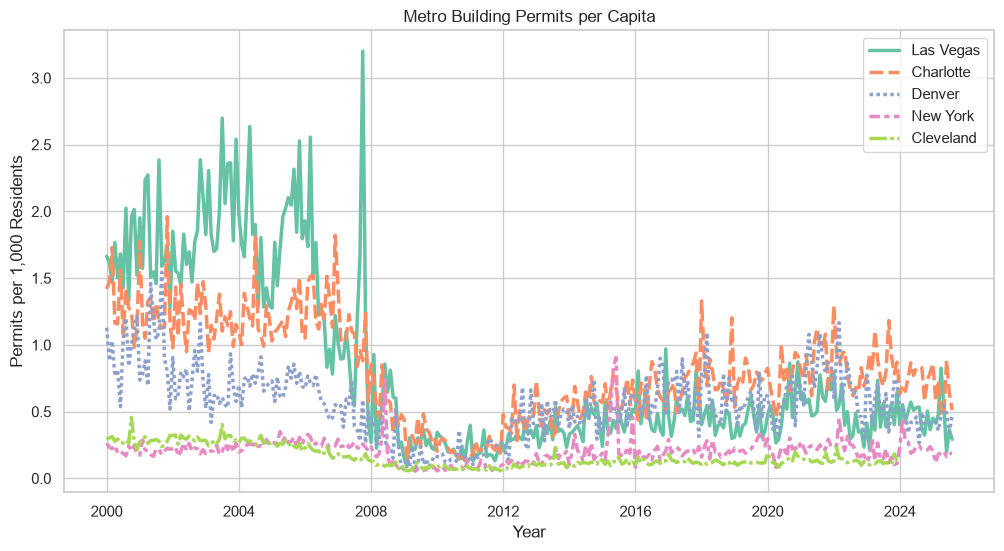

In [6]:
df_per_capita = compute_permits_per_capita(df_visuals)

plots.plot_national_permits_per_capita(df_per_capita)
plots.plot_metro_permits_per_capita(df_per_capita)

### 2.3 Case-Shiller House Price Indices, 1987/01–2007/07
All indices are normalized to `2000/01 = 100`. The figure shows the variation the model has to explain: a boom in Las Vegas, New York and the 10-City Composite, against steady growth in Charlotte and Denver and very little appreciation in Cleveland.

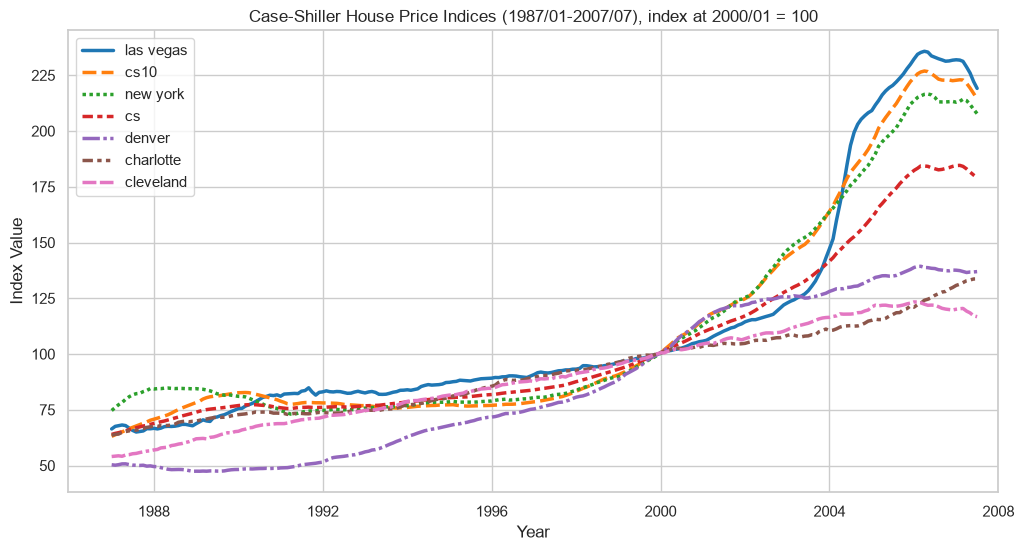

In [7]:
plots.plot_house_price_indices(df_var)

### 2.4 Macroeconomic Indicators
The three macro variables in each VAR are the FFR, Trimmed Mean PCE inflation and the unemployment rate. The FFR fell from 6.4% in December 2000 to about 1% by late 2003, while inflation stayed subdued.

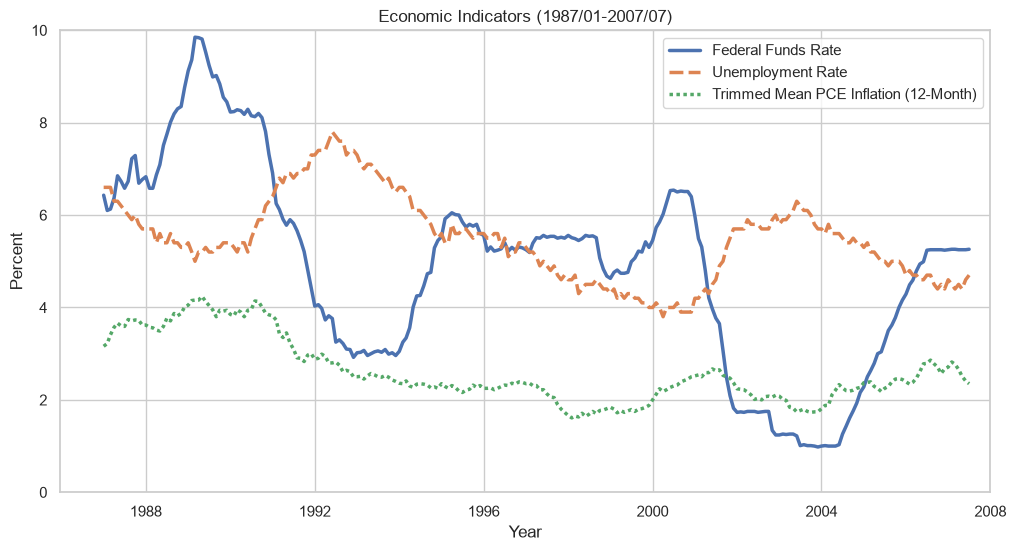

In [8]:
plots.plot_economic_indicators(df_var)

## 3. Structural VAR Methodology & Orthogonalized Impulse Responses (Figure 22)

### 3.1 Reduced-Form VAR(12)
Following Kilian & Lütkepohl (2017, Ch. 2, Eq. 2.2.4), each model is

$$y_t = \nu + A_1 y_{t-1} + \dots + A_{12} y_{t-12} + u_t, \quad u_t \sim (0, \Sigma_u)$$

with $K = 4$, $p = 12$ and $y_t = [\text{unemp}_t,\ \text{pce}_t,\ \text{ffr}_t,\ \log(\text{hpi}_t)]'$. With $N = 247$ observations, the effective sample is $T = 235$ (`1988/01` to `2007/07`).

- **Levels.** Even with I(1) variables and cointegration, OLS slope estimators remain consistent and asymptotically normal for $p > 1$ (Sims, Stock & Watson, 1990; Kilian & Lütkepohl, 2017, Section 2.3.5, pp. 41–42). Estimating in levels avoids over-differencing or a misspecified cointegration rank.
- **Fixed lag order.** $p = 12$ captures a full year of monetary transmission and avoids post-model-selection inference distortions (Leeb & Pötscher, 2005; Kilian & Lütkepohl, 2017, Section 2.6.5, pp. 61–64).

### 3.2 Recursive Cholesky Identification
Structural shocks $w_t$ with $\mathbb{E}(w_t w_t') = I_K$ relate to the reduced-form innovations through $u_t = B_0^{-1} w_t$, where $B_0^{-1} = P = \text{chol}(\tilde{\Sigma}_u)$ is lower triangular (Kilian & Lütkepohl, 2017, Ch. 4, pp. 109–112):

$$
\begin{bmatrix} u_t^{\text{unemp}} \\ u_t^{\text{pce}} \\ u_t^{\text{ffr}} \\ u_t^{\text{hpi}} \end{bmatrix}
=
\begin{bmatrix}
b_{11} & 0 & 0 & 0 \\
b_{21} & b_{22} & 0 & 0 \\
b_{31} & b_{32} & b_{33} & 0 \\
b_{41} & b_{42} & b_{43} & b_{44}
\end{bmatrix}
\begin{bmatrix} w_{1t} \\ w_{2t} \\ w_{3t} \\ w_{4t} \end{bmatrix}
$$

Ordering unemployment and inflation before the FFR embeds a backward-looking Taylor Rule: the Fed reacts within the month to both, while they respond to policy with at least a one-month lag. Ordering house prices last lets them react immediately to all three macro variables, while the Fed does not target them contemporaneously ($b_{34} = 0$). The responses to $w_{3t}$, the monetary policy shock, do not depend on the ordering of the variables before the FFR (Christiano, Eichenbaum & Evans, 1999, 2005).

### 3.3 Impulse Responses from the Companion Form
With the $Kp \times Kp$ ($48 \times 48$) companion matrix $A$ and the selection matrix $J = [I_K,\ 0_{K \times K(p-1)}]$, the reduced-form VMA weights and the structural impulse responses are (Kilian & Lütkepohl, 2017, Section 4.1, pp. 110–112)

$$\Phi_i = J A^i J', \qquad \Theta_i = \Phi_i B_0^-1 = J A^i J' B_0^-1, \quad i = 0, 1, \dots, 60$$

The object of interest is the response of log house prices to a one standard deviation FFR shock:

$$\theta_{43,i} = \frac{\partial \log(\text{hpi}_{t+i})}{\partial w_{3t}}$$

### 3.4 Stata-Compatible ML Covariance Scaling
`statsmodels` uses the OLS covariance estimator, while Stata's `var` command defaults to Gaussian maximum likelihood (Kilian & Lütkepohl, 2017, Section 2.3.1, Eq. 2.3.4, and Section 2.3.4, p. 40):

$$\hat{\Sigma}_u = \frac{1}{T - Kp - 1} \hat{U}\hat{U}' \qquad \text{vs.} \qquad \tilde{\Sigma}_u = \frac{1}{T} \hat{U}\hat{U}' = \frac{T - Kp - 1}{T} \hat{\Sigma}_u$$

With `df_resid` $= T - Kp - 1 = 235 - 49 = 186$, the `statsmodels` Cholesky factor is therefore multiplied by

$$\sqrt{\frac{T - Kp - 1}{T}} = \sqrt{\frac{186}{235}} \approx 0.88966$$

which puts the structural FFR shock on Stata's scale, at about 12.2–12.4 basis points across the seven models (see the last column of the table below).

### 3.5 Residual Bootstrap (500 Replications)
The confidence bands follow Stata's `irf create, step(60) bs reps(500)` (*[TS] irf create*, p. 26):

1. Condition on the $p = 12$ presample observations (`1987/01` to `1987/12`).
2. Resample the $T = 235$ residual vectors ($1 \times K$) with replacement, which preserves contemporaneous cross-equation correlation.
3. Recursively simulate a synthetic sample $y_t^*$.
4. Re-estimate the VAR(12) and the ML-scaled responses, and repeat $R = 500$ times.
5. Take the sample standard deviation across replications and form $\hat{\theta}_{43,i} \pm 1.96 \times \widehat{\text{SE}}_{\text{bs}}$.

In [9]:
irf_results = run_var_analysis(
    df_var_ready,
    cs_cols=config.CS_COLS,
    start_date=config.VAR_START_DATE,
    end_date=config.VAR_END_DATE,
    lags=config.VAR_LAGS,
    irf_steps=config.IRF_STEPS,
    n_boot=config.N_BOOTSTRAP,
    seed=config.BOOTSTRAP_SEED,
)

Sample Window (including 12 lags): 1987-01-01 to 2007-07-01
Model        | Eff. Obs (T) | FFR Residual SD  | FFR Cholesky Shock
------------------------------------------------------------------
cs           | 235          | 0.1267802        | 0.12360000        
cs10         | 235          | 0.1268970        | 0.12438087        
newyork      | 235          | 0.1261822        | 0.12374911        
lasvegas     | 235          | 0.1254066        | 0.12249494        
denver       | 235          | 0.1240484        | 0.12159632        
charlotte    | 235          | 0.1243224        | 0.12239021        
cleveland    | 235          | 0.1250870        | 0.12294897        


### 3.6 Figure 22: Response of House Prices to an FFR Shock

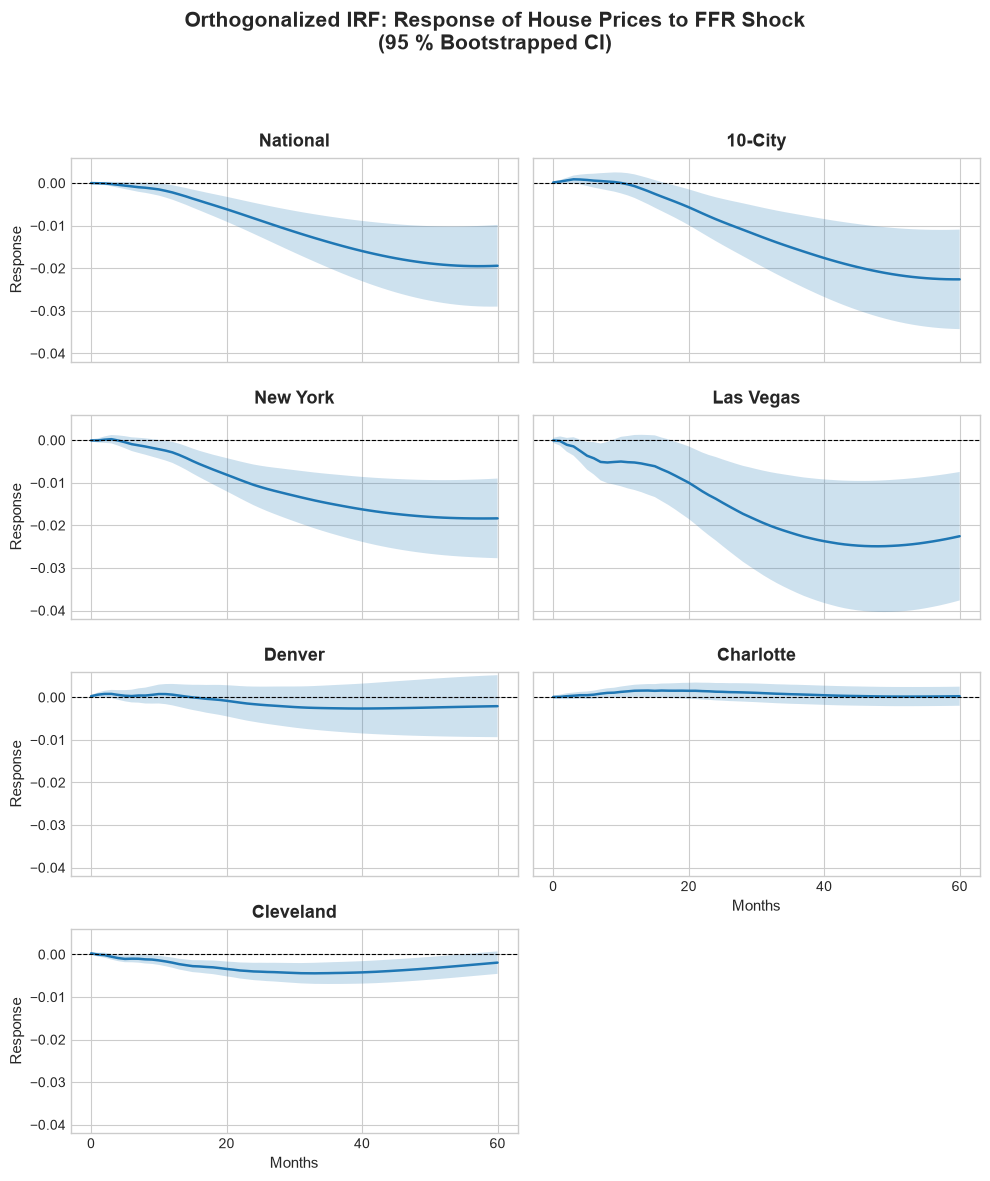

In [10]:
plots.plot_irf_grid(irf_results, config.CS_NAMES)

**Interpretation.** Values are the response of log house prices to a 1-SD (about 12 basis point) FFR shock, multiplied by 100 to read as percent. "Significant" means the 95% band lies entirely below zero.

- **National:** trough of −1.95% at 57 months, significant at 51 of 61 horizons. The effect is large and still near its trough at five years.
- **10-City:** the largest aggregate response, −2.26% at 60 months, significant at 44 horizons.
- **New York:** −1.84% at 58 months, significant at 50 horizons. With inelastic supply, demand changes cannot be absorbed by construction, so they show up as strong, persistent price effects.
- **Las Vegas:** the largest response of all, −2.49% at 48 months, significant at 47 horizons, with the widest band. Land supply is elastic, but construction and prices boomed together. The thesis diagnostics (high residual volatility with ARCH effects, and no cointegration) point to decoupling from macroeconomic fundamentals.
- **Denver:** trough of only −0.26% at 40 months and never significantly negative. New construction met the additional demand.
- **Charlotte:** close to zero throughout, at most 0.16% in absolute value and never significantly negative, for the same reason.
- **Cleveland:** small but significant, with a trough of −0.44% at 33 months and 51 significant horizons. With excess housing stock and prices below replacement cost, the response reflects national macro fundamentals.

## 4. Empirical Counterfactual Simulation: Taylor Rule Baseline (Figures 21 & 23)

Standard historical decompositions for stationary models cannot be applied to I(1) variables in levels, because the initial-condition transients do not die out. Following Kilian & Lütkepohl (2017, p. 120), the notebook instead simulates in-sample counterfactual paths with the structural policy shock set to zero, $w_{3t}^{cf} = 0$, from $T^* = $ `2001/01` through `2007/07`. Earlier shocks and all non-policy structural shocks stay at their historical values:

$$y_t^{cf} = \hat{\nu} + \sum_{i=1}^{12} \hat{A}_i y_{t-i}^{cf} + \hat{B}_0^{-1} w_t^{cf}, \qquad
w_t^{cf} = \begin{cases} w_t & \text{if } t < T^* \\ (w_{1t},\ w_{2t},\ 0,\ w_{4t})' & \text{if } t \ge T^* \end{cases}$$

With no policy shocks, the FFR follows only the estimated systematic reaction to unemployment and inflation, which serves as the Taylor Rule baseline. A 3-variable VAR without house prices provides a benchmark for that FFR path.

In the table below, `Peak Diff` is how far the actual peak lies above the counterfactual peak, relative to the counterfactual peak.

In [11]:
df_3var = run_3var_counterfactual(df_var_ready)
cf_results = run_counterfactual_analysis(df_var_ready)

Counterfactual Simulation: Structural FFR Shock = 0 from 2001-01-01
Model        | Actual Peak HPI  | CF Peak HPI    | Peak Diff (%) 
----------------------------------------------------------------
cs           | 184.60           | 153.77         | +20.04        %
cs10         | 226.90           | 180.48         | +25.72        %
newyork      | 216.62           | 179.53         | +20.66        %
lasvegas     | 235.76           | 191.25         | +23.27        %
denver       | 139.34           | 134.66         | +3.48         %
charlotte    | 133.68           | 133.90         | -0.17         %
cleveland    | 123.36           | 119.76         | +3.00         %


### 4.1 Figure 21: Actual and Counterfactual Federal Funds Rate
Both counterfactuals keep the FFR well above its actual path during 2002–2004. In June 2003, when the actual monthly rate was 1.22%, the counterfactual was 2.49% in the national model and 2.35% in the 3-variable benchmark. The two counterfactual paths nearly coincide through 2004. They diverge after 2005, when the national model stays about one percentage point below the benchmark.

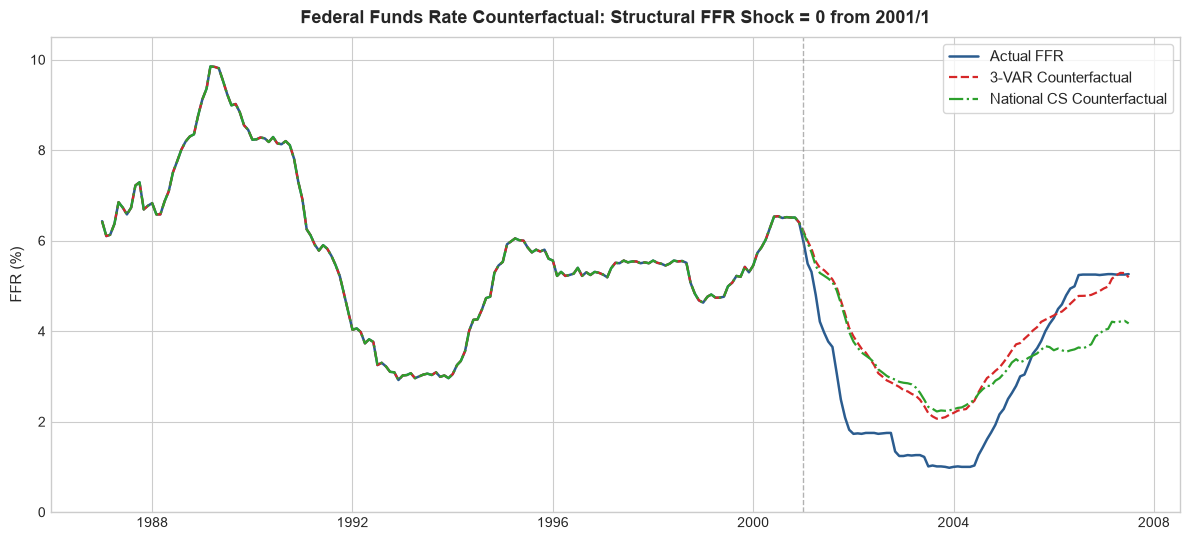

In [12]:
plots.plot_ffr_counterfactual_comparison(cf_results, df_3var)

### 4.2 Figure 23: Actual and Counterfactual House Prices
The panels follow the order used in the thesis.

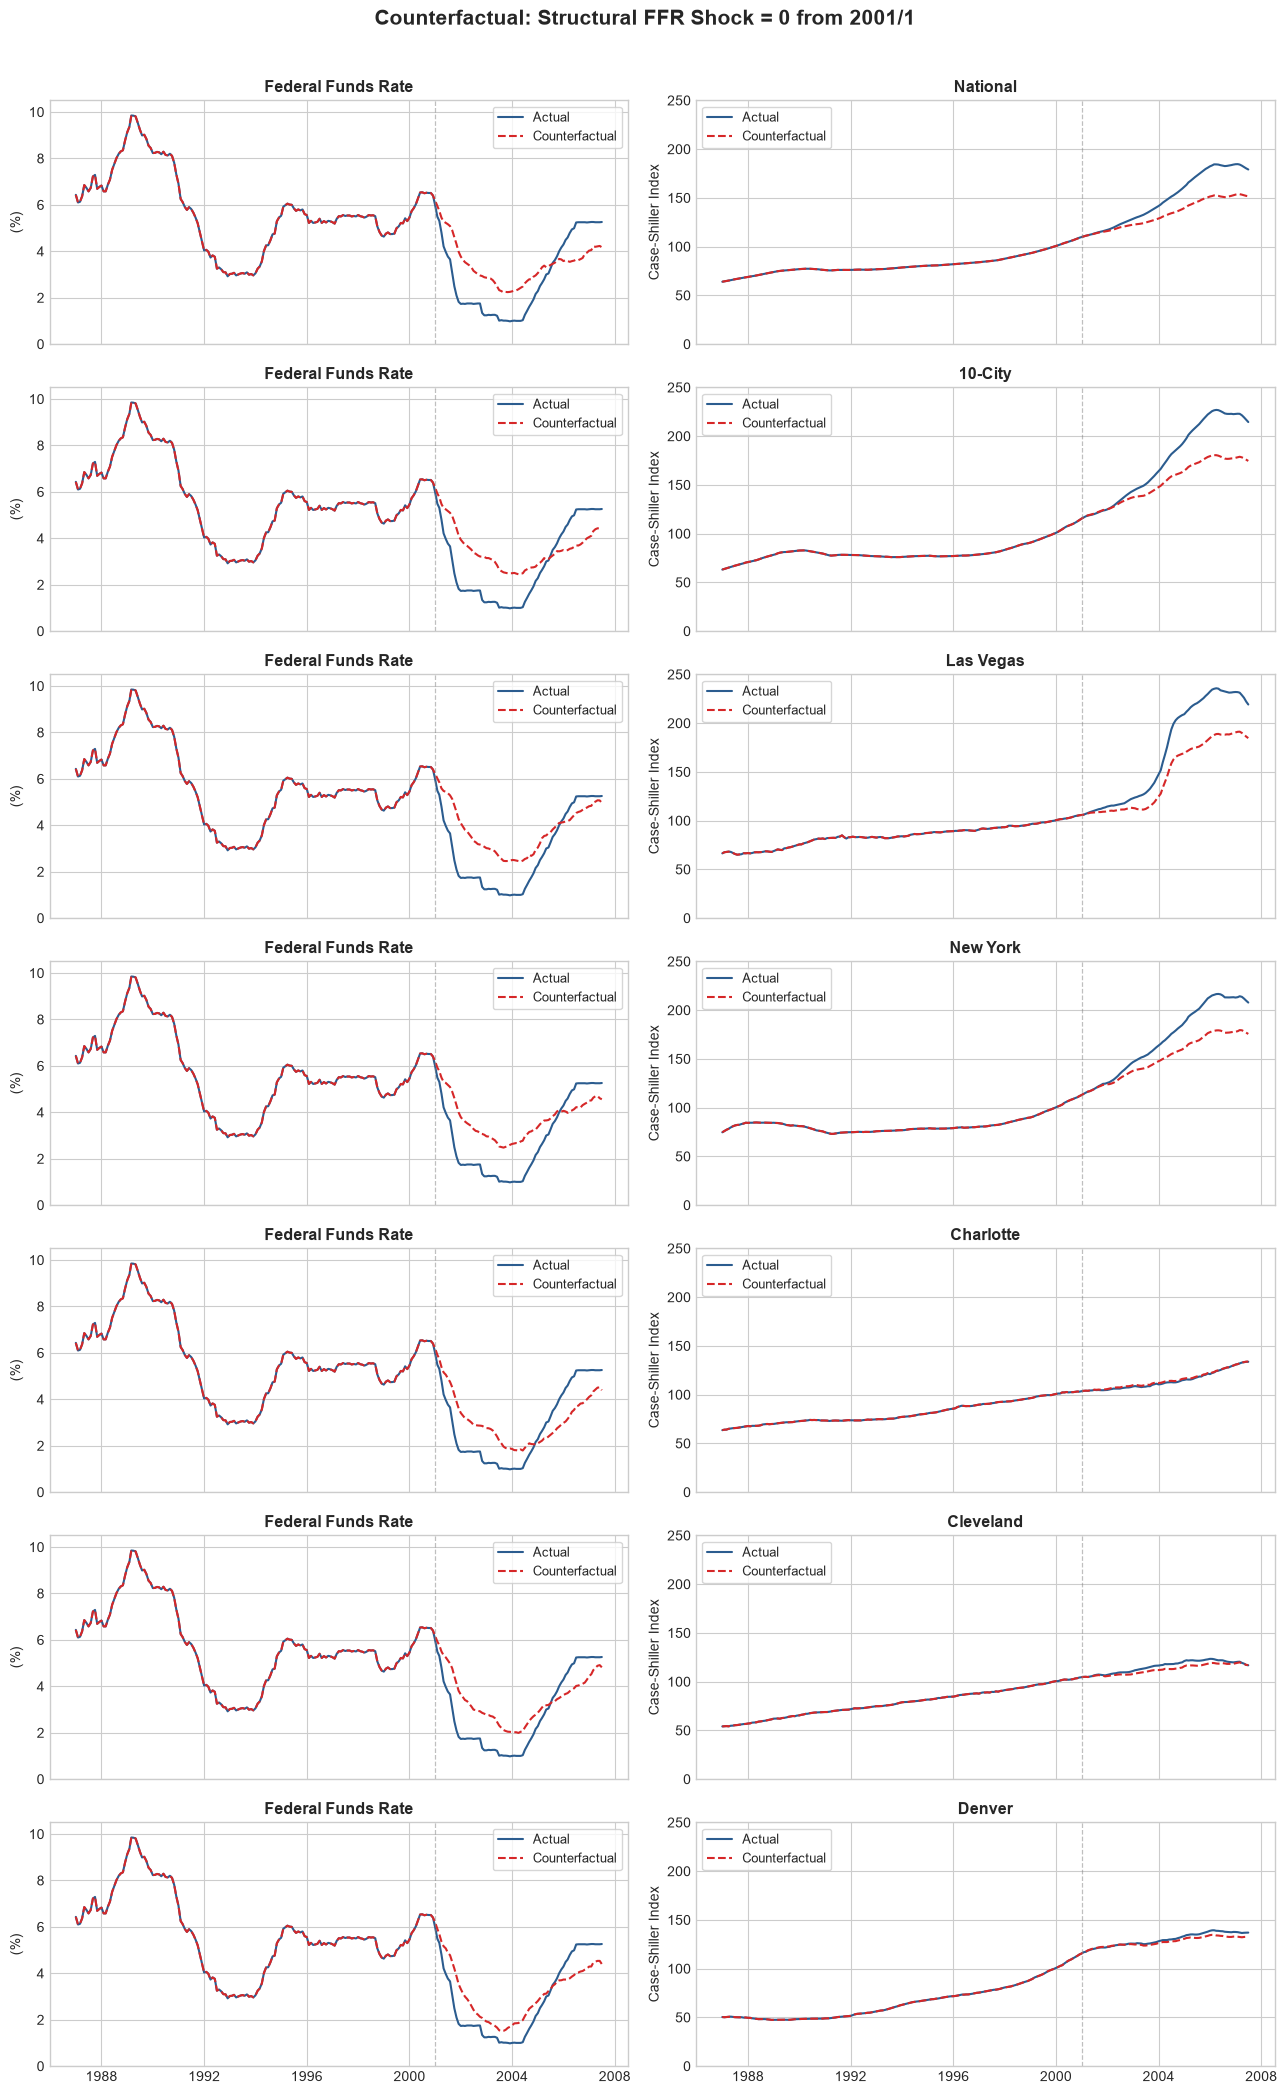

In [13]:
thesis_order = ['cs', 'cs10', 'lasvegas', 'newyork', 'charlotte', 'cleveland', 'denver']
cf_results = {name: cf_results[name] for name in thesis_order}

plots.plot_counterfactual_grid(cf_results)

**Key takeaways**

- **Large effects in the aggregates and New York.** Actual peaks lie 20.0% (National), 25.7% (10-City) and 20.7% (New York) above their counterfactual peaks. Put the other way, without the policy shocks those peaks would have been 17–20% lower.
- **Almost no effect in elastic markets.** The peak in Charlotte is unchanged (−0.2%) and in Denver it differs by only 3.5%. Cleveland is similar at 3.0%.
- **Las Vegas keeps its kink.** The actual peak is 23.3% above the counterfactual, but the sharp acceleration from mid-2003 remains even with policy shocks removed. Six-month price growth rises from about −2% in June 2003 to 25% a year later on the counterfactual path. That persistence is consistent with the PLS credit supply surge and speculative buying rather than with the interest rate alone.

The transmission of monetary policy to house prices therefore depended strongly on local supply conditions and, in markets such as Las Vegas, on credit dynamics that a policy rate counterfactual does not remove.